# DeepLabV3 Segmentation Pipeline -- Evaluation

Standalone evaluation of the DeepLabV3-ResNet50 leaf/plant segmenter (trained in
`leaf_segmentation.ipynb`) feeding the masked-ResNet50 growth-stage classifier, as a
sequential pipeline (segment -> mask -> classify). Extracted from the DeepLabV3-specific
cells of `unet_leaf_pipeline_comparison.ipynb` so this model can be evaluated on its own,
without the U-Net comparison machinery.

Nothing is retrained here -- only existing checkpoints in `checkpoints_segmentation/` and
`export_leaf_pipeline/` are loaded and (re-)scored.

In [1]:
import os
import json

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torchvision import models, transforms
from torchvision.models.segmentation import deeplabv3_resnet50
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
random_state = np.random.RandomState(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [2]:
# ---- Resolved paths ----
PROJECT_ROOT = r"d:\Reasearch\Resnet50test"

CLASSIFIER_CKPT_PATH = os.path.join(PROJECT_ROOT, "checkpoints_masked", "resnet50_masked_best.pt")

DEEPLABV3_CKPT_PATH = os.path.join(PROJECT_ROOT, "checkpoints_segmentation", "deeplabv3_leaf_seg_best.pt")
DEEPLABV3_EXPORT_DIR = os.path.join(PROJECT_ROOT, "export_leaf_pipeline")

TEST_DIR = os.path.join(PROJECT_ROOT, "tomato final dataset", "test")
TEST_COCO_JSON = os.path.join(TEST_DIR, "_annotations.coco.json")

CLASS_NAMES = ["developing", "flowering", "fruiting", "seeding"]
IMAGE_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

for p in [CLASSIFIER_CKPT_PATH, DEEPLABV3_CKPT_PATH, TEST_COCO_JSON]:
    assert os.path.exists(p), f"missing: {p}"
print("All resolved paths exist.")

All resolved paths exist.


## Segmentation-quality metric functions

`foreground_iou_dice` scores the plant class only. `both_class_mean_iou` averages
background-class IoU and plant-class IoU -- matching how DeepLabV3's originally reported
75.7% was computed in `leaf_segmentation.ipynb`.

In [3]:
def foreground_iou_dice(pred_binary, target_binary, eps=1e-6):
    """pred_binary, target_binary: numpy arrays, same shape, values in {0,1}. Plant-class-only."""
    pred = pred_binary.astype(np.float32).flatten()
    target = target_binary.astype(np.float32).flatten()
    intersection = (pred * target).sum()
    union = pred.sum() + target.sum() - intersection
    iou = (intersection + eps) / (union + eps)
    dice = (2 * intersection + eps) / (pred.sum() + target.sum() + eps)
    return float(iou), float(dice)


def both_class_mean_iou(pred_binary, target_binary):
    """Average of background-class IoU and plant-class IoU, matching leaf_segmentation.ipynb's
    mean_iou() (how DeepLabV3's 75.7% was originally reported)."""
    ious = []
    for c in (0, 1):
        pred_c = pred_binary == c
        target_c = target_binary == c
        intersection = np.logical_and(pred_c, target_c).sum()
        union = np.logical_or(pred_c, target_c).sum()
        if union == 0:
            continue
        ious.append(intersection / union)
    return float(sum(ious) / len(ious)) if ious else 0.0

## Load the masked-trained ResNet50 classifier (91.87% oracle-mask accuracy)

In [4]:
classifier = models.resnet50(weights=None)
classifier.fc = nn.Linear(classifier.fc.in_features, len(CLASS_NAMES))
clf_state = torch.load(CLASSIFIER_CKPT_PATH, map_location=device, weights_only=False)
# checkpoints_masked/resnet50_masked_best.pt is a dict wrapper {model_state_dict, class_names, epoch, val_acc}
state_dict = clf_state["model_state_dict"] if isinstance(clf_state, dict) and "model_state_dict" in clf_state else clf_state
classifier.load_state_dict(state_dict)
classifier = classifier.to(device).eval()
print("Classifier loaded.")

Classifier loaded.


## Test-set listing

Every test image with >=1 COCO annotation, needed for ground-truth mask rasterization
below.

In [5]:
from segmentation_dataset_utils import build_binary_mask  # full-res polygon rasterization, reused as-is

with open(TEST_COCO_JSON, encoding="utf-8") as f:
    test_coco = json.load(f)

fname_to_image = {im["file_name"]: im for im in test_coco["images"]}
anns_by_image_id = {}
for ann in test_coco["annotations"]:
    anns_by_image_id.setdefault(ann["image_id"], []).append(ann)


def list_test_samples():
    """(path, class_name, image_entry) for every test image with >=1 annotation. Logs skips."""
    samples = []
    skipped = []
    for cls in CLASS_NAMES:
        class_dir = os.path.join(TEST_DIR, cls)
        for fname in sorted(os.listdir(class_dir)):
            if not fname.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            image_entry = fname_to_image.get(fname)
            if image_entry is None or not anns_by_image_id.get(image_entry["id"]):
                skipped.append((cls, fname, "no matching COCO annotation"))
                continue
            samples.append((os.path.join(class_dir, fname), cls, image_entry))
    return samples, skipped

test_samples, skipped_samples = list_test_samples()
print(f"Test samples with annotation: {len(test_samples)} | skipped: {len(skipped_samples)}")
for cls, fname, reason in skipped_samples:
    print(f"  [skip] {cls}/{fname}: {reason}")

Test samples with annotation: 160 | skipped: 0


## Segmentation quality: DeepLabV3 on the held-out test set (both metrics)

Reuses the existing trained checkpoint (`checkpoints_segmentation/deeplabv3_leaf_seg_best.pt`)
-- no retraining. Uses DeepLabV3's own Resize(256)->CenterCrop(224) convention (its own
eval transform).

In [6]:
deeplabv3_model = deeplabv3_resnet50(weights=None, aux_loss=True)
deeplabv3_model.classifier[4] = nn.Conv2d(256, 2, kernel_size=1)
deeplabv3_model.aux_classifier[4] = nn.Conv2d(256, 2, kernel_size=1)
dlv3_ckpt = torch.load(DEEPLABV3_CKPT_PATH, map_location=device, weights_only=False)
deeplabv3_model.load_state_dict(dlv3_ckpt["model_state_dict"])
deeplabv3_model = deeplabv3_model.to(device).eval()

dlv3_eval_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.CenterCrop(IMAGE_SIZE),
])
dlv3_to_tensor_norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def deeplabv3_gt_mask_224(image_entry, cropped_size):
    """Ground truth must go through the SAME Resize+CenterCrop geometry as the image for
    DeepLabV3's own convention. Rasterize at full res, apply matching resize+crop via PIL,
    nearest-neighbor to keep it binary."""
    anns = anns_by_image_id[image_entry["id"]]
    full_mask = build_binary_mask(image_entry["height"], image_entry["width"], anns)
    mask_img = Image.fromarray(full_mask * 255)
    resized = transforms.functional.resize(mask_img, int(IMAGE_SIZE * 1.14), interpolation=transforms.InterpolationMode.NEAREST)
    cropped = transforms.functional.center_crop(resized, IMAGE_SIZE)
    return (np.array(cropped) > 127).astype(np.uint8)


@torch.no_grad()
def deeplabv3_predict_mask(path):
    img = Image.open(path).convert("RGB")
    img_cropped = dlv3_eval_transform(img)
    tensor = dlv3_to_tensor_norm(img_cropped).unsqueeze(0).to(device)
    logits = deeplabv3_model(tensor)["out"]
    pred = logits.argmax(dim=1).cpu().squeeze().numpy().astype(np.uint8)
    return pred


dlv3_fg_ious, dlv3_fg_dices, dlv3_both_ious = [], [], []
per_stage_dlv3 = {c: {"fg_iou": [], "fg_dice": [], "both_iou": []} for c in CLASS_NAMES}

for path, cls, image_entry in test_samples:
    pred_mask = deeplabv3_predict_mask(path)
    target_mask = deeplabv3_gt_mask_224(image_entry, IMAGE_SIZE)

    fg_iou, fg_dice = foreground_iou_dice(pred_mask, target_mask)
    both_iou = both_class_mean_iou(pred_mask, target_mask)

    dlv3_fg_ious.append(fg_iou)
    dlv3_fg_dices.append(fg_dice)
    dlv3_both_ious.append(both_iou)
    per_stage_dlv3[cls]["fg_iou"].append(fg_iou)
    per_stage_dlv3[cls]["fg_dice"].append(fg_dice)
    per_stage_dlv3[cls]["both_iou"].append(both_iou)

print("=== DeepLabV3 segmentation quality (test set, both metrics) ===")
print(f"Foreground-only IoU:  {np.mean(dlv3_fg_ious):.4f}")
print(f"Foreground-only Dice: {np.mean(dlv3_fg_dices):.4f}")
print(f"Both-class mean IoU:  {np.mean(dlv3_both_ious):.4f}   (should be close to the originally reported 0.7570)")
print()
for cls in CLASS_NAMES:
    d = per_stage_dlv3[cls]
    print(f"  {cls:<12} fg_iou={np.mean(d['fg_iou']):.4f}  fg_dice={np.mean(d['fg_dice']):.4f}  "
          f"both_iou={np.mean(d['both_iou']):.4f}  n={len(d['fg_iou'])}")

=== DeepLabV3 segmentation quality (test set, both metrics) ===
Foreground-only IoU:  0.6204
Foreground-only Dice: 0.7536
Both-class mean IoU:  0.7475   (should be close to the originally reported 0.7570)

  developing   fg_iou=0.6840  fg_dice=0.7936  both_iou=0.7588  n=41
  flowering    fg_iou=0.5906  fg_dice=0.7353  both_iou=0.7166  n=60
  fruiting     fg_iou=0.4904  fg_dice=0.6444  both_iou=0.6711  n=21
  seeding      fg_iou=0.6706  fg_dice=0.7996  both_iou=0.8266  n=38


## Full pipeline: segment -> mask -> classify

Uses the exact files in `export_leaf_pipeline/` (no retraining). Segments each test image
with DeepLabV3, blacks out the background, then classifies the masked image with the
DeepLabV3-paired ResNet50 classifier.

DeepLabV3 pipeline test accuracy (recomputed here): 0.8750  (originally reported: 0.8500)

              precision    recall  f1-score   support

  developing       0.95      1.00      0.98        41
   flowering       0.92      0.73      0.81        60
    fruiting       0.55      0.81      0.65        21
     seeding       1.00      1.00      1.00        38

    accuracy                           0.88       160
   macro avg       0.85      0.89      0.86       160
weighted avg       0.90      0.88      0.88       160



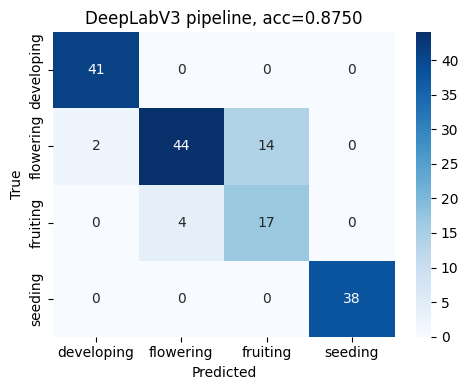

In [7]:
normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

dlv3_clf = models.resnet50(weights=None)
dlv3_clf.fc = nn.Linear(dlv3_clf.fc.in_features, len(CLASS_NAMES))
dlv3_clf_state = torch.load(os.path.join(DEEPLABV3_EXPORT_DIR, "resnet50_leaf_classifier.pth"), map_location=device, weights_only=True)
dlv3_clf.load_state_dict(dlv3_clf_state)
dlv3_clf = dlv3_clf.to(device).eval()

dlv3_raw_transform = transforms.Compose([
    transforms.Resize(int(IMAGE_SIZE * 1.14)),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
])

@torch.no_grad()
def predict_growth_stage_dlv3(image_path):
    img = Image.open(image_path).convert("RGB")
    raw = dlv3_raw_transform(img).unsqueeze(0).to(device)
    normed = normalize(raw.squeeze(0)).unsqueeze(0)
    pred_mask = deeplabv3_model(normed)["out"].argmax(dim=1, keepdim=True).float()
    masked_raw = raw * pred_mask
    masked_norm = normalize(masked_raw.squeeze(0)).unsqueeze(0)
    logits = dlv3_clf(masked_norm)
    probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
    return CLASS_NAMES[int(probs.argmax())]

dlv3_preds = [predict_growth_stage_dlv3(path) for path, cls, image_entry in test_samples]
dlv3_labels = [cls for path, cls, image_entry in test_samples]
pipeline_acc_dlv3 = np.mean(np.array(dlv3_preds) == np.array(dlv3_labels))

print(f"DeepLabV3 pipeline test accuracy (recomputed here): {pipeline_acc_dlv3:.4f}  "
      f"(originally reported: 0.8500)")
print()
print(classification_report(dlv3_labels, dlv3_preds, labels=CLASS_NAMES, target_names=CLASS_NAMES))

cm_dlv3 = confusion_matrix(dlv3_labels, dlv3_preds, labels=CLASS_NAMES)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_dlv3, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"DeepLabV3 pipeline, acc={pipeline_acc_dlv3:.4f}")
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_ROOT, "deeplabv3_pipeline_confusion_matrix_recomputed.png"), dpi=150)
plt.show()

## Summary

- Segmentation quality (foreground IoU/Dice, both-class mean IoU) per class and overall.
- End-to-end pipeline accuracy against the held-out test set.
- Confusion matrix saved to `deeplabv3_pipeline_confusion_matrix_recomputed.png`.

For a head-to-head comparison against U-Net, see `unet_leaf_pipeline_comparison.ipynb`.